# 모의고사 3회 · 온라인 강의 수료 예측 (분류)
AICE 2주 합격 플랜 · 영상 13편. 공식 샘플(분류형)과 같은 구조의 14문항입니다. **90분 타이머를 켜고** 시험처럼 푸세요.
- 도메인: 온라인 강의 · 목표: 수강생이 강의를 마칠지(Pass) 못 마칠지(Fail) 맞히는 모델 만들기 (정답이 종류라서 **분류**)
- 문항에 변수명이 주어지면 반드시 그 이름을 쓰세요. 빈칸 문제는 빈칸에 들어갈 말을 답안 변수에 저장하세요. 준비 칸에 없는 도구는 답 칸에서 직접 import 하세요.

| 컬럼 | 설명 |
|---|---|
| StudentID | 수강생 번호 |
| Result | 수료 여부(Pass/Fail), 정답 |
| Age | 나이 |
| Plan | 요금제 |
| Device | 주로 쓰는 기기 |
| JoinPath | 가입 경로 |
| LoginDays | 한 달 접속 일수 |
| StudyHours | 공부 시간(시간) |
| VideoRate | 영상 시청률(%) |
| QuizAvg | 퀴즈 평균 점수 |
| Questions | 질문 수 |

_최종 수정 2026-10-21 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 데이터 내려받기
아래 셀을 먼저 실행하세요.

In [1]:
!wget -q -O mock3_course.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/mock3_course.csv
import os
print('준비 완료' if os.path.exists('mock3_course.csv') and os.path.getsize('mock3_course.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


## <데이터 분석>
### 1. 데이터 분석에 쓰는 판다스를 별칭 pd 로 불러오세요

In [2]:
import pandas as pd

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### 2. mock3_course.csv 를 읽어 데이터프레임 변수명 `data` 에 할당하고 첫 3개 행을 출력하세요

In [4]:
data = pd.read_csv('mock3_course.csv')
data.head(3)

,StudentID,Result,Age,Plan,Device,JoinPath,LoginDays,StudyHours,VideoRate,QuizAvg,Questions
0,S300000,Fail,36,Free,Mobile,Search,8,5.1,28.6,71.2,2
1,S300001,Pass,41,Basic,Mobile,Friend,15,10.1,79.8,79.4,3
2,S300002,Fail,19,Premium,PC,Search,20,3.4,55.0,76.9,2


### 3. 요금제(Plan)별 수강생 수를 수료 여부(Result)로 나눠 countplot 으로 그리세요
- hue 를 쓰세요.
- Fail 이 Pass 보다 많은 요금제를 `답안3` 에 저장하세요. 예시) 답안3 = 'Basic'

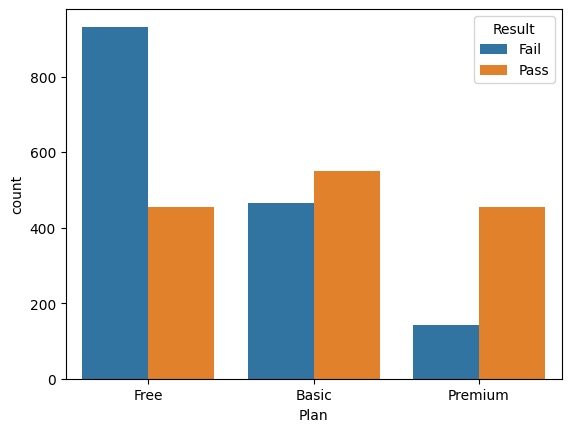

In [6]:
sns.countplot(data=data, x='Plan', hue='Result')
plt.show()

답안3 = 'Free'

### 4. 숫자 컬럼끼리의 상관계수를 heatmap 으로 그리려는데 에러가 납니다. 정정하세요
- 영상 시청률(VideoRate)과 상관계수가 가장 큰 컬럼(자기 자신 제외)을 `답안4` 에 저장하세요.

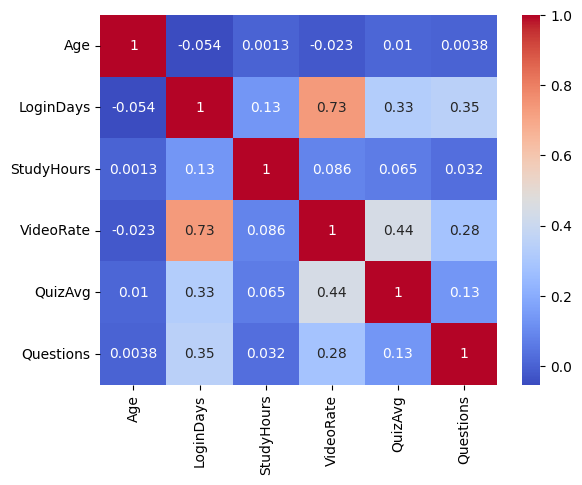

In [29]:
from numpy._core import numerictypes
# 아래의 코드를 정정하고 실행하세요.
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

답안4 = 'LoginDays'

## <데이터 전처리>
### 5. 공부 시간(StudyHours)의 IQR 이상치를 삭제하고 수강생 번호(StudentID) 컬럼도 삭제하세요
- 이상치: Q1 - 1.5×IQR 보다 작거나 Q3 + 1.5×IQR 보다 큰 값
- 결과는 `data_temp` 에 저장하고 reset_index 로 번호를 다시 매기세요(drop=True).
- 남은 행 수를 `답안5` 에 저장하세요.

In [12]:
q1 = data['StudyHours'].quantile(0.25)
q3 = data['StudyHours'].quantile(0.75)
iqr = q3 - q1

cond = (data['StudyHours'] < q1 - 1.5 * iqr)|(data['StudyHours'] > q3 + 1.5 * iqr) # 공부시간 StudyHours의 이상치
data_temp = data.drop(data[cond].index, axis=0) # IQR이상치 삭제
data_temp = data_temp.drop(columns=['StudentID']) # 수강생 번호 StudentID 컬럼 삭제
data_temp.reset_index(drop=True, inplace=True) # 번호 다시 매기기
답안5 = len(data_temp)
답안5

2876

### 6. 결측치를 처리해 `data_na` 에 저장하세요
- 퀴즈 평균(QuizAvg)의 결측치는 **중앙값으로 채우고**, 그 뒤에 남은 결측치가 있는 행을 삭제하세요.
- 남은 행 수를 `답안6` 에 저장하세요.

In [13]:
print(data_temp.isnull().sum())
data_na = data_temp.copy()
data_na['QuizAvg'] = data_na['QuizAvg'].fillna(data_na['QuizAvg'].median()) # 퀴즈 평균(QuizAvg)의 결측치를 중앙값으로 채움
data_na = data_na.dropna() # 남은 결측치가 있는 행을 삭제

답안6 = len(data_na)
답안6

Result          0
Age             0
Plan            0
Device         47
JoinPath        0
LoginDays       0
StudyHours      0
VideoRate       0
QuizAvg       142
Questions       0
dtype: int64


2829

### 7. 가입 경로(JoinPath)의 'SNS|Instagram', 'SNS|YouTube' 를 'SNS' 로 합치고, 범주 컬럼을 원 핫 인코딩하세요
- 합친 뒤 SNS 의 개수를 `답안7` 에 저장하세요.
- 인코딩 코드에 오류가 1곳 있습니다. 정정하고 결과를 `data_preset` 에 저장하세요.

In [ ]:
# 합친다 loc -> [data_na에 있는 ['Joinpath']의 isin 칼럼들 (인스타그램, 유튜브)를 가입경로에다가] -> SNS 라고
data_na.loc[data_na['JoinPath'].isin(['SNS|Instagram', 'SNS|YouTube']),['JoinPath']] = 'SNS'
답안7 = data_na['JoinPath'].value_counts()['SNS']
답안7

In [14]:
# 아래의 코드를 정정하고 실행하세요.
data_preset = pd.get_dummies(data=data_na, columns=['Plan', 'Device', 'JoinPath'])
data_preset.head(2)

,Result,Age,LoginDays,StudyHours,VideoRate,QuizAvg,Questions,Plan_Basic,Plan_Free,Plan_Premium,Device_Mobile,Device_PC,Device_Tablet,JoinPath_Ad,JoinPath_Friend,JoinPath_SNS,JoinPath_SNS|Instagram,JoinPath_SNS|YouTube,JoinPath_Search
0,Fail,36,8,5.1,28.6,71.2,2,False,True,False,True,False,False,False,False,False,False,False,True
1,Pass,41,15,10.1,79.8,79.4,3,True,False,False,True,False,False,False,True,False,False,False,False


### 8. Result 를 레이블 y, 나머지를 피처 X 로 하고 학습용·검증용을 나누세요
- 변수: `X_train, X_valid, y_train, y_valid` · 비율 75:25 · 난수 시드 7 · 레이블 비율 유지

In [15]:
from  sklearn.model_selection import train_test_split
X = data_preset.drop('Result', axis=1)
y = data_preset['Result']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=7, stratify=y)

### 9. StandardScaler 로 스케일링하세요
- 빈칸 `< blank9-1 >`, `< blank9-2 >` 를 채우세요.
- 스케일링된 학습 데이터의 표준편차를 소수 첫째 자리까지 반올림해 `답안9` 에 저장하세요.
- 이 셀은 X_train, X_valid 를 덮어씁니다. 다시 실행할 때는 8번 셀부터 다시 실행하세요.

In [16]:
# 아래 코드의 빈칸을 채우고 실행하세요.
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
답안9 = round(np.std(X_train), 1)
답안9

np.float64(1.0)

## <AI 모델링>
### 10. RandomForest 분류 모델로 GridSearchCV 를 하세요
- 후보: n_estimators [100, 200], max_depth [5, 10] · cv=3 · scoring='accuracy' · 모델 난수 시드 42 · 결과는 `gs_rf`
- 가장 좋은 max_depth 를 `답안10` 에 저장하세요.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

gs_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid={'n_estimators':[100,200], 'max_depth':[5,10]}, cv=3, scoring='accuracy')
gs_rf.fit(X_train, y_train)

print(gs_rf.best_params_)

답안10 = gs_rf.best_params_['max_depth']
답안10

{'max_depth': 10, 'n_estimators': 200}


10

### 11. 가장 좋은 RandomForest 의 변수 중요도 top 5 를 막대그래프로 그리고, 1위 피처 이름을 `답안11` 에 저장하세요

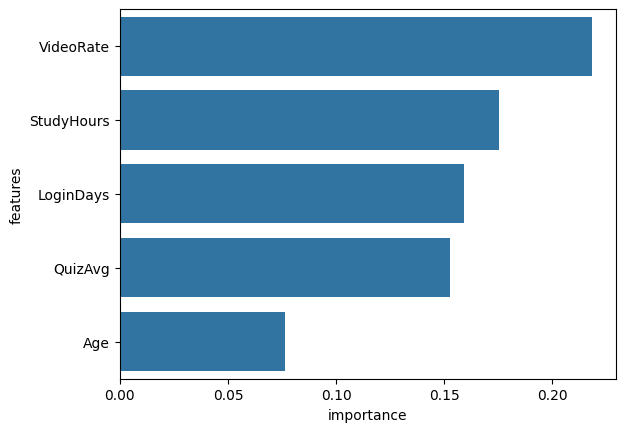

'VideoRate'

In [20]:
fi = pd.DataFrame({'features':X.columns, 'importance':gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:5]
sns.barplot(data=fi, x='importance', y='features')
plt.show()

답안11 = fi.iloc[0]['features']
답안11

### 12. XGBoost 모델(`xgb`)을 학습하려는데 에러가 납니다. 정정하고, 두 모델의 검증 정확도를 비교하세요
- XGBClassifier: n_estimators 100, 난수 시드 42
- 정답을 숫자로 바꾼 값은 `y_train_n`, `y_valid_n` 에 저장하세요(LabelEncoder).
- 정확도가 더 높은 모델 이름을 `답안12` 에 저장하세요 ('RandomForest' 또는 'XGBoost').

In [23]:
# 아래의 코드를 정정하고 실행하세요.
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_n = le.fit_transform(y_train)
y_valid_n = le.transform(y_valid)

xgb = XGBClassifier(n_estimators=100, random_state=42)
xgb.fit(X_train, y_train_n)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [24]:
from sklearn.metrics import accuracy_score

rf_acc = accuracy_score(y_valid, gs_rf.best_estimator_.predict(X_valid))
xgb_acc = accuracy_score(y_valid_n, xgb.predict(X_valid))
print(rf_acc, xgb_acc)

답안12 = 'RandomForest' if rf_acc > xgb_acc else 'XGBoost'
답안12

0.7598870056497176 0.7288135593220338


'RandomForest'

### 다음 문항을 풀기 전에 아래 코드를 실행하세요.

In [25]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
tf.keras.utils.set_random_seed(1)

### 13. 수료 여부를 예측하는 딥러닝 모델을 만들고 학습하세요
- 정답은 12번의 `y_train_n`, `y_valid_n`(0 과 1)을 그대로 씁니다. to_categorical 은 쓰지 않습니다.
- 구조: Dense 64 (relu, input_dim) → Dropout 0.2 → Dense 32 (relu) → 출력층
- compile: optimizer adam, loss binary_crossentropy, metrics accuracy · EarlyStopping: val_loss 가 5번 나아지지 않으면 멈춤 · 학습: epochs 50, batch_size 64, 검증 데이터 지정 · 학습 정보는 `history`
- 빈칸에 들어갈 값을 `답안13_1`(숫자), `답안13_2`(문자열)에 저장하세요.
- 이 셀을 다시 실행하려면 위 준비 칸부터 다시 실행하세요(모델이 이어서 학습돼요).
- 결과 숫자와 멈추는 바퀴 수는 컴퓨터마다 조금 다를 수 있어요.

In [27]:
# 아래 코드의 빈칸을 채우고 실행하세요.
model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
estop = EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train_n, epochs=50, batch_size=64, validation_data=(X_valid, y_valid_n), callbacks=[estop])

답안13_1 = 1
답안13_2 = 'sigmoid'

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6351 - loss: 0.6345 - val_accuracy: 0.7514 - val_loss: 0.5430
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7393 - loss: 0.5331 - val_accuracy: 0.7599 - val_loss: 0.5027
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7511 - loss: 0.5090 - val_accuracy: 0.7641 - val_loss: 0.4954
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7562 - loss: 0.5027 - val_accuracy: 0.7585 - val_loss: 0.4941
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7600 - loss: 0.4977 - val_accuracy: 0.7599 - val_loss: 0.4943
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7492 - loss: 0.5016 - val_accuracy: 0.7613 - val_loss: 0.4934
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7511 - loss: 0.4969 - val_accuracy: 0.7585 - val_loss: 0.4927
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7652 - loss: 0.4924 - val_accuracy: 0.7571 - val_loss

### 14. 학습 정확도와 검증 정확도의 변화를 한 그래프에 그리세요
- 범례 'accuracy', 'val_accuracy' · 제목 'Model Accuracy' · x축 'Epoch' · y축 'Accuracy'
- 빈칸 `< blank14-1 >`, `< blank14-2 >` 에 들어갈 말을 `답안14_1`, `답안14_2` 에 저장하세요.

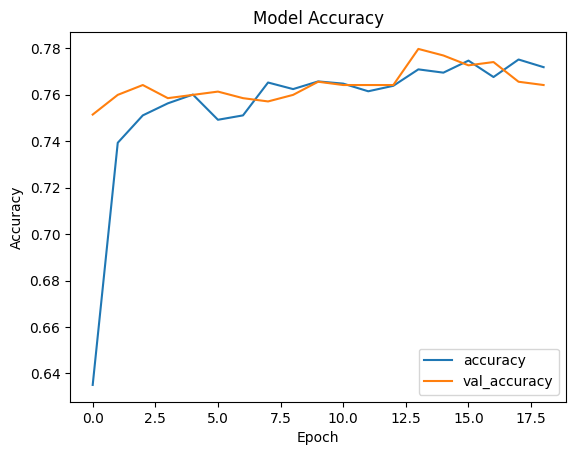

In [31]:
# 아래 코드의 빈칸을 채우고 실행하세요.
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['accuracy', 'val_accuracy'])
plt.show()

답안14_1 = 'accuracy'
답안14_2 = 'val_accuracy'

---
### 모든 문항이 끝났습니다.
- 해설 노트북과 영상 13편으로 채점해 보세요. 마지막 층 1칸(0/1 정답)과 2칸(to_categorical)의 차이는 영상 13편 표로 다시 정리하세요.